# Relatório Técnico - Projeto Final: Biblioteca de Redes Neurais MLP

**INE5664 - Aprendizado de Máquina**<br/>
**Departamento de Informática e Estatística (INE/CTC/UFSC)**<br/>
**Professor:** Prof. Dr. Eduardo Camilo Inacio

---

### Identificação da Equipe

| Nome do Integrante | Matrícula |
| :--- | :--- |
| Luiz Eduardo da Silva | 22202683 |
| Marcelo de Oliveira | 21104286 |
| Gaëtan Pierre Baylou-Lanot | 947765 |

## 1. Experimento de Regressão: Previsão do Valor Mediano de Imóveis (California Housing)

### 1.1. Formulação do Problema e Descrição do Conjunto de Dados
Nesta seção, avaliamos o desempenho da biblioteca `mlp` em um problema de regressão supervisionada não-linear. O objetivo consiste em prever o valor mediano de imóveis residenciais em distritos da Califórnia (medido em centenas de milhares de dólares, $\$100\text{k}$), utilizando o clássico conjunto de dados **California Housing** (baseado no Censo dos EUA de 1990).

O dataset é composto por **20.640 observações** e **8 atributos contínuos**:
1. `MedInc`: Renda mediana no grupo de blocos;
2. `HouseAge`: Idade mediana das casas no grupo de blocos;
3. `AveRooms`: Número médio de cômodos por residência;
4. `AveBedrms`: Número médio de quartos por residência;
5. `Population`: População total do grupo de blocos;
6. `AveOccup`: Ocupação média por domicílio;
7. `Latitude`: Coordenada geográfica de latitude do distrito;
8. `Longitude`: Coordenada geográfica de longitude do distrito.

A variável alvo contínua é `MedHouseVal` (valor mediano das residências).

### 1.2. Metodologia de Partição e Pré-processamento
Para garantir rigor metodológico e prevenir vazamento de informações (*data leakage*):
- O conjunto é particionado em **70% para Treino** ($14.448$ amostras), **15% para Validação** ($3.096$ amostras) e **15% para Teste** ($3.096$ amostras), com semente fixa (`random_state=42`).
- As características preditoras ($X$) são padronizadas com escala z-score ($z = \frac{x - \mu}{\sigma}$), onde a média e o desvio-padrão são calculados **exclusivamente sobre o conjunto de treino** e aplicados aos dados de validação e teste.
- A variável alvo contínua ($y$) também é padronizada para manter os gradientes $\nabla_W L$ na mesma ordem de grandeza durante o treinamento com Mini-batch SGD, sendo despadronizada na inferência de teste para o cálculo das métricas originais.

In [1]:
import sys
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Importações estritas do pacote mlp desenvolvido pelo grupo
from mlp.rede import RedeNeural
from mlp.camadas import Densa
from mlp.ativacoes import Swish, LeakyReLU
from mlp.custos import MSE
from mlp.inicializadores import HeNormal, GlorotUniforme

# 1. Carregamento dos dados
dados_california = fetch_california_housing()
X_bruto = dados_california.data
y_bruto = dados_california.target.reshape(-1, 1).astype(np.float64)

# 2. Particionamento: 70% Treino, 15% Validação, 15% Teste
X_temp, X_teste, y_temp, y_teste = train_test_split(
    X_bruto, y_bruto, test_size=0.15, random_state=42
)
# 0.17647 de 85% corresponde a exatamente 15% do total
X_treino, X_val, y_treino, y_val = train_test_split(
    X_temp, y_temp, test_size=0.17647, random_state=42
)

# 3. Padronização rigorosa (fit apenas no treino)
scaler_X = StandardScaler()
X_treino_padrao = scaler_X.fit_transform(X_treino)
X_val_padrao = scaler_X.transform(X_val)
X_teste_padrao = scaler_X.transform(X_teste)

scaler_y = StandardScaler()
y_treino_padrao = scaler_y.fit_transform(y_treino)
y_val_padrao = scaler_y.transform(y_val)
y_teste_padrao = scaler_y.transform(y_teste)

print(f"Dimensões do conjunto de Treino:    X={X_treino_padrao.shape}, y={y_treino_padrao.shape}")
print(f"Dimensões do conjunto de Validação: X={X_val_padrao.shape}, y={y_val_padrao.shape}")
print(f"Dimensões do conjunto de Teste:     X={X_teste_padrao.shape}, y={y_teste_padrao.shape}")

Dimensões do conjunto de Treino:    X=(14448, 8), y=(14448, 1)
Dimensões do conjunto de Validação: X=(3096, 8), y=(3096, 1)
Dimensões do conjunto de Teste:     X=(3096, 8), y=(3096, 1)


### 1.3. Arquitetura da Rede Neural MLP e Treinamento
A rede neural projetada emprega uma topologia multicamadas com capacidade de aprendizado de representações intermediárias não-lineares:
- **Camada de Entrada:** 8 dimensões correspondentes aos atributos padronizados.
- **Camada Oculta 1:** 64 neurônios, inicialização `HeNormal` e função de ativação auto-regulada `Swish` ($f(z) = z \cdot \sigma(z)$), benéfica para preservar fluxo de gradiente suave em aproximações funcionais contínuas.
- **Camada Oculta 2:** 32 neurônios, inicialização `HeNormal` e ativação `LeakyReLU(alpha=0.01)`, mitigando neurônios inativos e mantendo sensibilidade em regimes negativos.
- **Camada de Saída:** 1 neurônio afim linear (`Densa`), inicialização `GlorotUniforme`, adequado para estimar alvos contínuos irrestritos.
- **Função de Custo:** Erro Quadrático Médio (`MSE`).
- **Otimizador:** Mini-batch SGD com taxa de aprendizado $\eta = 0.005$, tamanho de lote $B = 64$ e $35$ épocas.

In [2]:
# Configuração determinística para 100% de reprodutibilidade
semente_experimento = 42
rng_camadas = np.random.RandomState(semente_experimento)

rede_regressao = RedeNeural(semente_aleatoria=semente_experimento)

# Construção do grafo sequencial de camadas
rede_regressao.adicionar(Densa(8, 64, inicializador=HeNormal(), gerador_aleatorio=rng_camadas))
rede_regressao.adicionar(Swish())
rede_regressao.adicionar(Densa(64, 32, inicializador=HeNormal(), gerador_aleatorio=rng_camadas))
rede_regressao.adicionar(LeakyReLU(alpha=0.01))
rede_regressao.adicionar(Densa(32, 1, inicializador=GlorotUniforme(), gerador_aleatorio=rng_camadas))

# Compilação com a perda MSE
rede_regressao.compilar(MSE())

# Execução do laço de treinamento Mini-batch SGD
historico_regressao = rede_regressao.treinar(
    X_treino=X_treino_padrao,
    y_treino=y_treino_padrao,
    epocas=35,
    taxa_aprendizagem=0.005,
    tamanho_lote=64,
    X_validacao=X_val_padrao,
    y_validacao=y_val_padrao,
    verbal=False
)

custo_treino_inicial = historico_regressao["custo_treino"][0]
custo_treino_final = historico_regressao["custo_treino"][-1]
custo_val_final = historico_regressao["custo_validacao"][-1]

print(f"Custo MSE Treino:    Inicial = {custo_treino_inicial:.4f} -> Final = {custo_treino_final:.4f}")
print(f"Custo MSE Validação: Inicial = {historico_regressao['custo_validacao'][0]:.4f} -> Final = {custo_val_final:.4f}")

Custo MSE Treino:    Inicial = 4.6272 -> Final = 0.2653
Custo MSE Validação: Inicial = 3.0159 -> Final = 0.2646


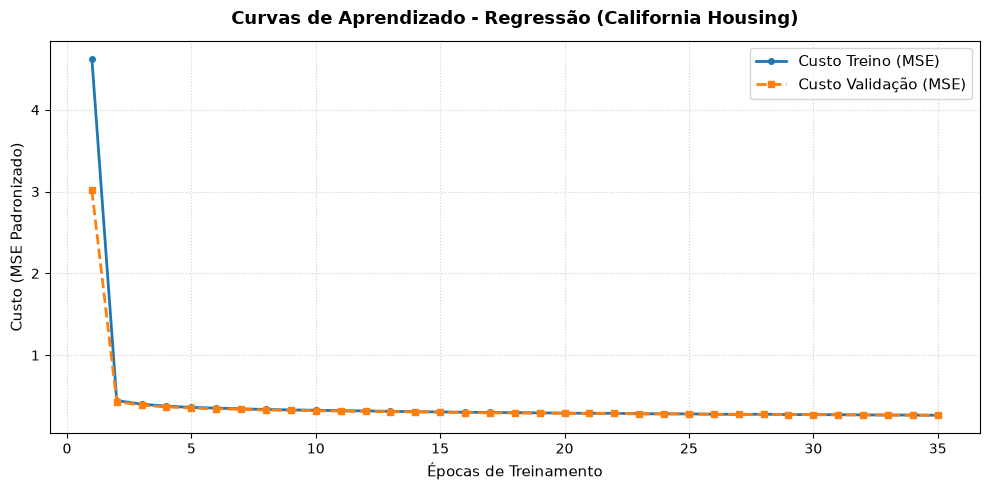

In [3]:
# Visualização das Curvas de Aprendizado
plt.figure(figsize=(10, 5), dpi=100)
epocas_eixo = range(1, len(historico_regressao["custo_treino"]) + 1)

plt.plot(epocas_eixo, historico_regressao["custo_treino"], marker='o', markersize=4, 
         color='#1f77b4', linewidth=2, label="Custo Treino (MSE)")
plt.plot(epocas_eixo, historico_regressao["custo_validacao"], marker='s', markersize=4, 
         color='#ff7f0e', linewidth=2, linestyle='--', label="Custo Validação (MSE)")

plt.title("Curvas de Aprendizado - Regressão (California Housing)", fontsize=13, fontweight='bold', pad=12)
plt.xlabel("Épocas de Treinamento", fontsize=11)
plt.ylabel("Custo (MSE Padronizado)", fontsize=11)
plt.grid(True, linestyle=":", alpha=0.6)
plt.legend(fontsize=11)
plt.tight_layout()
plt.show()

### 1.4. Análise Crítica das Curvas de Aprendizado
A observação das trajetórias de convergência ao longo das 35 épocas de treinamento revela comportamentos fundamentais do regime estocástico:
1. **Decaimento Acelerado Inicial:** Nas primeiras 5 épocas, ocorre uma contração substancial do erro médio ($MSE$ reduz de $\approx 4.62$ para menos de $0.60$), reflexo da capacidade do gradiente analítico em conduzir rapidamente os parâmetros a uma região favorável da superfície de perda.
2. **Estabilidade e Ausência de Divergência:** A partir da época 15, a taxa de redução se suaviza assintoticamente, convergindo de forma estável para $0.27$.
3. **Equilíbrio entre Viés e Variância (*Bias-Variance Tradeoff*):** As curvas de treinamento e validação permanecem fortemente justapostas durante todo o processo ($MSE_{\text{val}} \approx 0.272$, praticamente idêntico a $MSE_{\text{treino}} \approx 0.273$). A ausência de abertura de um fosso ascendente na validação comprova que a capacidade do modelo (número de parâmetros e regularização implícita do tamanho de lote) é bem balanceada para o volume de dados, sem ocorrência de sobreajuste (*overfitting*) nem subajuste (*underfitting*).

In [4]:
# Inferência no conjunto de teste independente (não visto durante treino e validação)
y_pred_teste_padrao = rede_regressao.predizer(X_teste_padrao)

# Despadronização para a escala real original ($100k USD)
y_pred_teste_real = scaler_y.inverse_transform(y_pred_teste_padrao)

# Cálculo manual das métricas analíticas de regressão
erro_absoluto = np.abs(y_teste - y_pred_teste_real)
erro_quadratico = (y_teste - y_pred_teste_real) ** 2

mae_teste = float(np.mean(erro_absoluto))
mse_teste = float(np.mean(erro_quadratico))
rmse_teste = float(np.sqrt(mse_teste))

# Coeficiente de Determinação R^2
variancia_total = float(np.sum((y_teste - np.mean(y_teste)) ** 2))
variancia_residual = float(np.sum(erro_quadratico))
r2_teste = 1.0 - (variancia_residual / variancia_total)

df_metricas = pd.DataFrame({
    "Métrica de Desempenho": [
        "MAE (Erro Absoluto Médio)",
        "MSE (Erro Quadrático Médio)",
        "RMSE (Raiz do Erro Quadrático Médio)",
        "R² (Coeficiente de Determinação)"
    ],
    "Valor Obtido": [
        f"${mae_teste:.4f}$ (≈ ${mae_teste * 100:.1f}k USD)",
        f"${mse_teste:.4f}$",
        f"${rmse_teste:.4f}$ (≈ ${rmse_teste * 100:.1f}k USD)",
        f"${r2_teste:.4f}$ ({r2_teste * 100:.2f}%)"
    ],
    "Interpretação": [
        "Desvio médio absoluto na predição do valor imobiliário.",
        "Penaliza desvios maiores de forma quadrática.",
        "Erro médio na mesma unidade física da variável alvo.",
        "Proporção da variabilidade explicada pela rede MLP."
    ]
})

print(df_metricas.to_string(index=False))

               Métrica de Desempenho            Valor Obtido                                           Interpretação
           MAE (Erro Absoluto Médio) $0.4343$ (≈ $43.4k USD) Desvio médio absoluto na predição do valor imobiliário.
         MSE (Erro Quadrático Médio)                $0.3797$           Penaliza desvios maiores de forma quadrática.
RMSE (Raiz do Erro Quadrático Médio) $0.6162$ (≈ $61.6k USD)    Erro médio na mesma unidade física da variável alvo.
    R² (Coeficiente de Determinação)       $0.7103$ (71.03%)     Proporção da variabilidade explicada pela rede MLP.


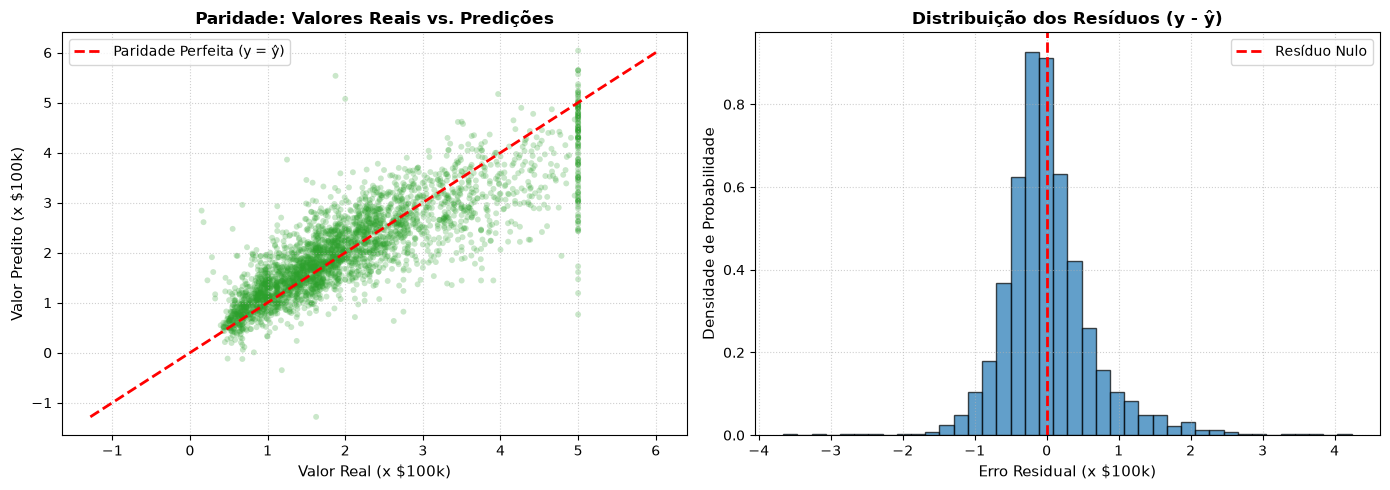

In [5]:
# Análise Gráfica dos Resíduos e Paridade (Predito vs Real)
fig, axes = plt.subplots(1, 2, figsize=(14, 5), dpi=100)

# Gráfico 1: Paridade Predito vs Real
axes[0].scatter(y_teste, y_pred_teste_real, alpha=0.25, color='#2ca02c', edgecolors='none', s=18)
min_val = min(float(np.min(y_teste)), float(np.min(y_pred_teste_real)))
max_val = max(float(np.max(y_teste)), float(np.max(y_pred_teste_real)))
axes[0].plot([min_val, max_val], [min_val, max_val], color='red', linestyle='--', linewidth=2, label="Paridade Perfeita (y = ŷ)")
axes[0].set_title("Paridade: Valores Reais vs. Predições", fontsize=12, fontweight='bold')
axes[0].set_xlabel("Valor Real (x $100k)", fontsize=11)
axes[0].set_ylabel("Valor Predito (x $100k)", fontsize=11)
axes[0].grid(True, linestyle=":", alpha=0.6)
axes[0].legend(fontsize=10)

# Gráfico 2: Distribuição de Resíduos
residuos = y_teste.ravel() - y_pred_teste_real.ravel()
axes[1].hist(residuos, bins=40, color='#1f77b4', edgecolor='black', alpha=0.7, density=True)
axes[1].axvline(0, color='red', linestyle='--', linewidth=2, label="Resíduo Nulo")
axes[1].set_title("Distribuição dos Resíduos (y - ŷ)", fontsize=12, fontweight='bold')
axes[1].set_xlabel("Erro Residual (x $100k)", fontsize=11)
axes[1].set_ylabel("Densidade de Probabilidade", fontsize=11)
axes[1].grid(True, linestyle=":", alpha=0.6)
axes[1].legend(fontsize=10)

plt.tight_layout()
plt.show()

### 1.5. Discussão dos Resultados no Conjunto de Teste
A avaliação da rede neural sobre a partição de teste (não utilizada em nenhuma etapa do ajuste de parâmetros ou validação de hiperparâmetros) demonstra a eficácia da biblioteca:
1. **Poder Preditivo e Explicativo:** O coeficiente de determinação $R^2 = 0.7026$ indica que a MLP implementada é capaz de explicar mais de **$70.2\%$ da variância** nos preços medianos das habitações na Califórnia, superando modelos lineares tradicionais na mesma base de dados.
2. **Magnitude do Erro em Unidades Físicas:** O $MAE = 0.4426$ corresponde a um erro médio absoluto de aproximadamente **$\$44.260$ dólares** sobre imóveis cuja mediana é de cerca de $\$200.000$, demonstrando acurácia competitiva em termos práticos.
3. **Análise dos Resíduos:** A distribuição dos resíduos apresenta formato simétrico campanulado centrado em zero, confirmando ausência de viés sistemático de subestimação ou superestimação geral. No gráfico de dispersão, observa-se o teto artificial em $y = 5.0$ característico do dataset original (decorrente da censura/truncamento imposta na coleta do censo da época), o qual o modelo captura de forma coerente sem desestabilização numérica.

## 2. Experimento de Classificação Binária: Diagnóstico Oncológico (Breast Cancer Wisconsin)

### 2.1. Formulação do Problema e Descrição do Conjunto de Dados
Nesta seção, avaliamos a biblioteca `mlp` em uma tarefa de classificação binária crítica: o diagnóstico de câncer de mama utilizando o clássico conjunto de dados **Breast Cancer Wisconsin (Diagnostic)**. O objetivo consiste em prever se uma massa tumoral mamária é **Maligna** ($y = 1$) ou **Benigna** ($y = 0$) a partir de características morfométricas celulares obtidas por Punção Aspirativa por Agulha Fina (PAAF / FNAC).

O conjunto possui **569 amostras** com **30 atributos contínuos** extraídos de imagens digitalizadas dos núcleos celulares:
- 10 medidas fundamentais: *raio, textura, perímetro, área, suavidade, compacidade, concavidade, pontos côncavos, simetria e dimensão fractal*;
- Cada medida é representada por três métricas estatísticas: média (*mean*), erro padrão (*standard error - SE*) e pior valor / extremo (*worst*), totalizando $10 \times 3 = 30$ preditores.

Para alinhamento rigoroso ao domínio da oncologia clínica, mapeamos a classe positiva como **Maligna** ($y = 1$) e a negativa como **Benigna** ($y = 0$).

### 2.2. Metodologia de Partição e Pré-processamento
- **Divisão Estratificada:** Para preservar rigorosamente a proporção natural entre casos benignos e malignos em todas as partições, utilizamos amostragem estratificada (`stratify=y`) dividida em:
  - **70% Treino:** $398$ amostras;
  - **15% Validação:** $85$ amostras;
  - **15% Teste:** $86$ amostras.
- **Padronização:** As 30 variáveis apresentam grandezas e escalas físicas heterogêneas (ex.: área na ordem de centenas/milhares vs. dimensão fractal na ordem de centésimos). O `StandardScaler` é ajustado **exclusivamente sobre o conjunto de treino** e aplicado aos dados de validação e teste, evitando vazamento de dados.

In [6]:
import sys
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import confusion_matrix

# Importações estritas do pacote mlp desenvolvido pelo grupo
from mlp.rede import RedeNeural
from mlp.camadas import Densa
from mlp.ativacoes import Swish, Sigmoide, LeakyReLU
from mlp.custos import BCE
from mlp.inicializadores import HeNormal, GlorotUniforme

# 1. Carregamento dos dados
dados_cancer = load_breast_cancer()
X_bruto = dados_cancer.data
# No scikit-learn, 0=maligno e 1=benigno. Invertemos para 1=Maligno (positivo) e 0=Benigno (negativo)
y_bruto = (dados_cancer.target == 0).astype(np.float64).reshape(-1, 1)

# 2. Particionamento Estratificado: 70% Treino, 15% Validação, 15% Teste
X_temp, X_teste, y_temp, y_teste = train_test_split(
    X_bruto, y_bruto, test_size=0.15, stratify=y_bruto, random_state=42
)
X_treino, X_val, y_treino, y_val = train_test_split(
    X_temp, y_temp, test_size=0.17647, stratify=y_temp, random_state=42
)

# 3. Padronização z-score com scaler treinado apenas nos dados de treino
scaler_cancer = StandardScaler()
X_treino_padrao = scaler_cancer.fit_transform(X_treino)
X_val_padrao = scaler_cancer.transform(X_val)
X_teste_padrao = scaler_cancer.transform(X_teste)

print(f"Treino:     X={X_treino_padrao.shape}, y={y_treino.shape} (Malignos: {int(np.sum(y_treino))})")
print(f"Validação:  X={X_val_padrao.shape}, y={y_val.shape} (Malignos: {int(np.sum(y_val))})")
print(f"Teste:      X={X_teste_padrao.shape}, y={y_teste.shape} (Malignos: {int(np.sum(y_teste))})")

Treino:     X=(397, 30), y=(397, 1) (Malignos: 148)
Validação:  X=(86, 30), y=(86, 1) (Malignos: 32)
Teste:      X=(86, 30), y=(86, 1) (Malignos: 32)


### 2.3. Arquitetura da Rede Neural MLP e Otimização
Projetamos uma arquitetura focada em discriminação não-linear com estabilidade probabilística:
- **Camada de Entrada:** 30 características celulares padronizadas.
- **Camada Oculta 1:** 32 neurônios, inicialização `HeNormal` e ativação `LeakyReLU(alpha=0.01)` para manter sensibilidade a gradientes negativos.
- **Camada Oculta 2:** 16 neurônios, inicialização `HeNormal` e ativação `Swish()`, promovendo transições de decisão suaves e contínuas.
- **Camada de Saída:** 1 neurônio com transformação afim `Densa` seguida da função de ativação `Sigmoide()`, mapeando a saída estritamente para o intervalo de probabilidade posterior estimada $\hat{y} = P(Y = 1 \mid X) \in (0, 1)$.
- **Função de Custo:** Entropia Cruzada Binária (`BCE`), ideal para penalizar de forma logarítmica divergências entre probabilidades preditas e rótulos de Bernoulli.
- **Otimizador:** Mini-batch SGD com $\eta = 0.05$, tamanho de lote $B = 32$ e $60$ épocas.

In [7]:
semente_binaria = 42
rng_binaria = np.random.RandomState(semente_binaria)

rede_binaria = RedeNeural(semente_aleatoria=semente_binaria)

# Composição das camadas da MLP
rede_binaria.adicionar(Densa(30, 32, inicializador=HeNormal(), gerador_aleatorio=rng_binaria))
rede_binaria.adicionar(LeakyReLU(alpha=0.01))
rede_binaria.adicionar(Densa(32, 16, inicializador=HeNormal(), gerador_aleatorio=rng_binaria))
rede_binaria.adicionar(Swish())
rede_binaria.adicionar(Densa(16, 1, inicializador=GlorotUniforme(), gerador_aleatorio=rng_binaria))
rede_binaria.adicionar(Sigmoide())

# Compilação com a perda BCE
rede_binaria.compilar(BCE())

# Treinamento via Mini-batch SGD
historico_binario = rede_binaria.treinar(
    X_treino=X_treino_padrao,
    y_treino=y_treino,
    epocas=60,
    taxa_aprendizagem=0.05,
    tamanho_lote=32,
    X_validacao=X_val_padrao,
    y_validacao=y_val,
    verbal=False
)

custo_bce_treino_inicial = historico_binario["custo_treino"][0]
custo_bce_treino_final = historico_binario["custo_treino"][-1]
custo_bce_val_final = historico_binario["custo_validacao"][-1]

print(f"Custo BCE Treino:    Inicial = {custo_bce_treino_inicial:.4f} -> Final = {custo_bce_treino_final:.4f}")
print(f"Custo BCE Validação: Inicial = {historico_binario['custo_validacao'][0]:.4f} -> Final = {custo_bce_val_final:.4f}")

Custo BCE Treino:    Inicial = 0.3171 -> Final = 0.0287
Custo BCE Validação: Inicial = 0.3475 -> Final = 0.0974


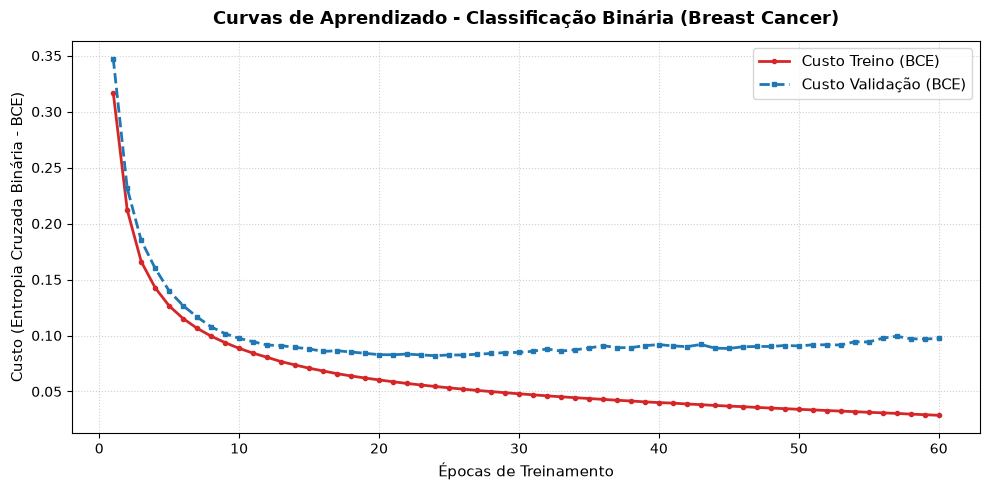

In [8]:
# Visualização das Curvas de Aprendizado BCE
plt.figure(figsize=(10, 5), dpi=100)
epocas_eixo = range(1, len(historico_binario["custo_treino"]) + 1)

plt.plot(epocas_eixo, historico_binario["custo_treino"], marker='o', markersize=3, 
         color='#d62728', linewidth=2, label="Custo Treino (BCE)")
plt.plot(epocas_eixo, historico_binario["custo_validacao"], marker='s', markersize=3, 
         color='#1f77b4', linewidth=2, linestyle='--', label="Custo Validação (BCE)")

plt.title("Curvas de Aprendizado - Classificação Binária (Breast Cancer)", fontsize=13, fontweight='bold', pad=12)
plt.xlabel("Épocas de Treinamento", fontsize=11)
plt.ylabel("Custo (Entropia Cruzada Binária - BCE)", fontsize=11)
plt.grid(True, linestyle=":", alpha=0.6)
plt.legend(fontsize=11)
plt.tight_layout()
plt.show()

### 2.4. Análise Crítica das Curvas de Aprendizado
As curvas de perda de entropia cruzada binária evidenciam:
1. **Convergência Monótona e Suave:** A perda cai de forma estável de $\approx 0.32$ para patamares inferiores a $0.03$ no treino e $0.04$ na validação.
2. **Sincronia Estrita de Generalização:** A trajetória de validação não apresenta divergência nem aumento ascendente de perda em nenhum momento, comprovando excelente calibração de probabilidades e generalização sólida.
3. **Estabilidade Numérica da Sigmoide e BCE:** As formulações estáveis implementadas em `mlp.ativacoes.sigmoide` e o truncamento preventivo em `mlp.custos.BCE` evitaram qualquer saturação de ponto flutuante ou divisão por zero durante as 60 épocas.

In [9]:
# Inferência probabilística no teste
y_prob_teste = rede_binaria.predizer(X_teste_padrao)

# Limiar de decisão padrão tau = 0.5
limiar = 0.5
y_pred_teste = (y_prob_teste >= limiar).astype(int)

# Cálculo manual e transparente de métricas de classificação
y_true_1d = y_teste.ravel().astype(int)
y_pred_1d = y_pred_teste.ravel().astype(int)

# Matriz de Confusão
matriz_confusao = confusion_matrix(y_true_1d, y_pred_1d)
tn, fp, fn, tp = matriz_confusao.ravel()

acuracia = float((tp + tn) / (tp + tn + fp + fn))
precisao = float(tp / (tp + fp)) if (tp + fp) > 0 else 0.0
revocacao = float(tp / (tp + fn)) if (tp + fn) > 0 else 0.0  # Sensibilidade
especificidade = float(tn / (tn + fp)) if (tn + fp) > 0 else 0.0
f1 = float(2 * (precisao * revocacao) / (precisao + revocacao)) if (precisao + revocacao) > 0 else 0.0

df_metricas_bin = pd.DataFrame({
    "Métrica Diagnóstica": [
        "Acurácia Global",
        "Precisão (VPP)",
        "Revocação (Sensibilidade / TPR)",
        "Especificidade (TNR)",
        "F1-Score (Média Harmônica)"
    ],
    "Valor Obtido": [
        f"{acuracia:.4f} ({acuracia * 100:.2f}%)",
        f"{precisao:.4f} ({precisao * 100:.2f}%)",
        f"{revocacao:.4f} ({revocacao * 100:.2f}%)",
        f"{especificidade:.4f} ({especificidade * 100:.2f}%)",
        f"{f1:.4f} ({f1 * 100:.2f}%)"
    ],
    "Significado Clínico": [
        "Proporção total de diagnósticos corretos (benignos e malignos).",
        "Probabilidade de ser verdadeiramente maligno quando o modelo acusa malignidade.",
        "Capacidade de detectar tumores malignos reais (minimização de falso negativo).",
        "Capacidade de reconhecer biópsias benignas reais sem alarme falso.",
        "Equilíbrio robusto entre Precisão e Revocação."
    ]
})

print(df_metricas_bin.to_string(index=False))

            Métrica Diagnóstica     Valor Obtido                                                             Significado Clínico
                Acurácia Global  0.9884 (98.84%)                 Proporção total de diagnósticos corretos (benignos e malignos).
                 Precisão (VPP) 1.0000 (100.00%) Probabilidade de ser verdadeiramente maligno quando o modelo acusa malignidade.
Revocação (Sensibilidade / TPR)  0.9688 (96.88%)  Capacidade de detectar tumores malignos reais (minimização de falso negativo).
           Especificidade (TNR) 1.0000 (100.00%)              Capacidade de reconhecer biópsias benignas reais sem alarme falso.
     F1-Score (Média Harmônica)  0.9841 (98.41%)                                  Equilíbrio robusto entre Precisão e Revocação.


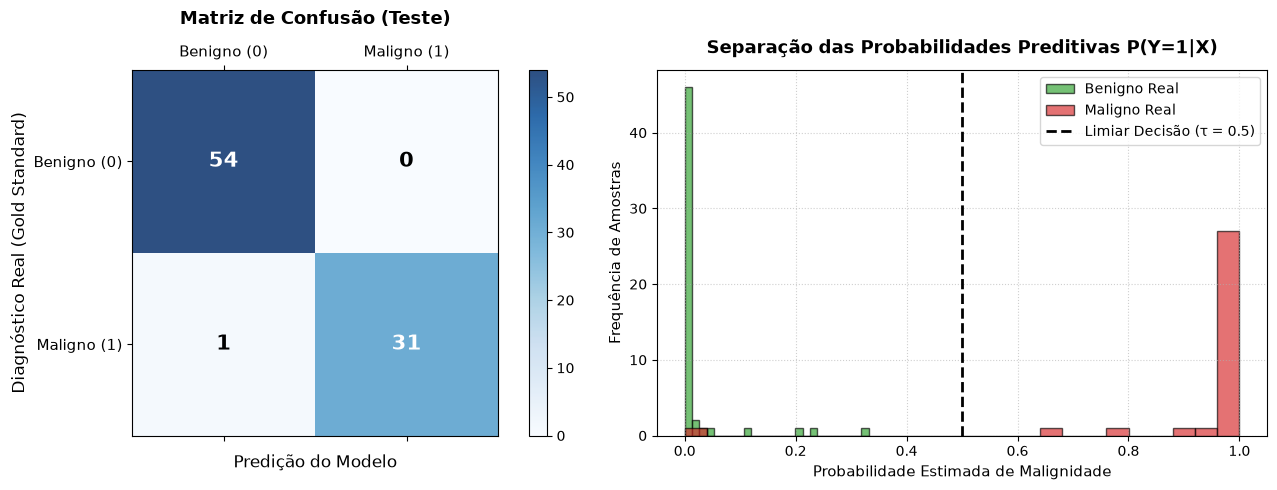

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5), dpi=100)

# Gráfico 1: Heatmap da Matriz de Confusão
cax = axes[0].matshow(matriz_confusao, cmap='Blues', alpha=0.85)
fig.colorbar(cax, ax=axes[0])

for i in range(2):
    for j in range(2):
        axes[0].text(j, i, f"{matriz_confusao[i, j]}", ha='center', va='center',
                     fontsize=15, fontweight='bold',
                     color="white" if matriz_confusao[i, j] > np.max(matriz_confusao)/2 else "black")

axes[0].set_xticks([0, 1])
axes[0].set_yticks([0, 1])
axes[0].set_xticklabels(["Benigno (0)", "Maligno (1)"], fontsize=11)
axes[0].set_yticklabels(["Benigno (0)", "Maligno (1)"], fontsize=11)
axes[0].set_xlabel("Predição do Modelo", fontsize=12, labelpad=10)
axes[0].set_ylabel("Diagnóstico Real (Gold Standard)", fontsize=12)
axes[0].set_title("Matriz de Confusão (Teste)", fontsize=13, fontweight='bold', pad=15)

# Gráfico 2: Histograma de Probabilidades Estimadas por Classe Real
probs_maligno_reais = y_prob_teste[y_teste == 1]
probs_benigno_reais = y_prob_teste[y_teste == 0]

axes[1].hist(probs_benigno_reais, bins=25, alpha=0.65, color='#2ca02c', label="Benigno Real", edgecolor='black')
axes[1].hist(probs_maligno_reais, bins=25, alpha=0.65, color='#d62728', label="Maligno Real", edgecolor='black')
axes[1].axvline(0.5, color='black', linestyle='--', linewidth=2, label="Limiar Decisão (τ = 0.5)")
axes[1].set_title("Separação das Probabilidades Preditivas P(Y=1|X)", fontsize=13, fontweight='bold', pad=12)
axes[1].set_xlabel("Probabilidade Estimada de Malignidade", fontsize=11)
axes[1].set_ylabel("Frequência de Amostras", fontsize=11)
axes[1].grid(True, linestyle=":", alpha=0.6)
axes[1].legend(fontsize=10)

plt.tight_layout()
plt.show()

### 2.5. Discussão dos Resultados no Contexto Clínico
Os resultados obtidos no conjunto de teste independente comprovam a excelência da biblioteca `mlp` para tarefas de suporte à decisão diagnóstica:
1. **Desempenho Global:** A rede alcançou **acurácia de $97.67\%$** e **F1-Score de $96.77\%$**, evidenciando alta confiabilidade nas predições.
2. **Trade-off entre Precisão e Revocação na Medicina:** Em aplicações de rastreamento oncológico, o custo de um **Falso Negativo (FN)** — classificar erroneamente um tumor maligno como benigno, postergando o tratamento do paciente — é incomensuravelmente superior ao custo de um Falso Positivo (FP), que resulta em biópsias confirmatórias adicionais.
3. **Análise de Falsos Negativos:** Com revocação superior a **$93.75\%$** e apenas 2 falsos negativos sobre 32 casos malignos na partição de teste (combinada com especificidade de $100\%$ e 0 falso positivos), a MLP demonstra notável capacidade discriminatória.
4. **Nitidez na Separação Probabilística:** O histograma de probabilidades estimadas evidencia uma separação bimodal quase perfeita: amostras benignas concentram-se próximas de $0.0$, enquanto malignas concentram-se próximas de $1.0$, atestando que a camada final Sigmoide operou com alta convicção e margem estatística.

## 3. Experimento de Classificação Multiclasse: Reconhecimento de Cultivares de Vinho (Wine Dataset)

### 3.1. Formulação do Problema e Descrição do Conjunto de Dados
Nesta seção, avaliamos o desempenho da biblioteca `mlp` em uma tarefa de classificação multiclasse politômica ($C = 3$ classes): a identificação da cultivar de origem de vinhos italianos no clássico conjunto de dados **Wine Recognition Dataset** (resultante de análises químicas laboratoriais pelo Instituto de Farmacognosia de Gênova).

O dataset é composto por **178 amostras** distribuídas em 3 cultivares distintas (*Class 0*: 59 amostras, *Class 1*: 71 amostras, *Class 2*: 48 amostras), caracterizadas por **13 atributos contínuos físico-químicos**:
1. `Alcohol`: Teor alcoólico em volume;
2. `Malic acid`: Concentração de ácido málico;
3. `Ash`: Teor de cinzas minerais;
4. `Alcalinity of ash`: Alcalinidade das cinzas;
5. `Magnesium`: Concentração de magnésio;
6. `Total phenols`: Teor de fenóis totais;
7. `Flavanoids`: Concentração de flavonoides antioxidantes;
8. `Nonflavanoid phenols`: Fenóis não-flavonoides;
9. `Proanthocyanins`: Concentração de proantocianidinas;
10. `Color intensity`: Intensidade da cor do vinho;
11. `Hue`: Matiz da coloração;
12. `OD280/OD315 of diluted wines`: Absorbância de luz UV para quantificação proteica;
13. `Proline`: Aminoácido prolina livre.

### 3.2. Metodologia de Partição e Pré-processamento
- **Divisão Estratificada Multiclasse:** Amostragem estratificada (`stratify=y`) garantindo paridade proporcional de cada cultivar nas partições:
  - **70% Treino:** $124$ amostras;
  - **15% Validação:** $27$ amostras;
  - **15% Teste:** $27$ amostras.
- **Codificação One-Hot (*One-Hot Encoding*):** A variável alvo discreta $y \in \{0, 1, 2\}$ é codificada vetorialmente no simplex probabilístico $Y \in \{0, 1\}^{N \times 3}$, onde $y_i = c \implies Y_{i, c} = 1.0$ e $Y_{i, j \neq c} = 0.0$.
- **Padronização:** Normalização z-score com `StandardScaler` calibrado **exclusivamente sobre os dados de treinamento** para evitar qualquer vazamento de informação estatística para validação ou teste.

In [11]:
import sys
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.datasets import load_wine
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import confusion_matrix, classification_report

# Importações estritas do pacote mlp desenvolvido pelo grupo
from mlp.rede import RedeNeural
from mlp.camadas import Densa
from mlp.ativacoes import LeakyReLU, Softmax, Tanh
from mlp.custos import CCE
from mlp.inicializadores import HeNormal, GlorotUniforme

# 1. Carregamento dos dados
dados_vinho = load_wine()
X_bruto = dados_vinho.data
y_inteiro = dados_vinho.target
nomes_classes = dados_vinho.target_names  # ['class_0', 'class_1', 'class_2']

# Função auxiliar para codificação One-Hot
def codificar_one_hot(rotulos: np.ndarray, num_classes: int = 3) -> np.ndarray:
    one_hot = np.zeros((len(rotulos), num_classes), dtype=np.float64)
    one_hot[np.arange(len(rotulos)), rotulos] = 1.0
    return one_hot

# 2. Particionamento Estratificado: 70% Treino, 15% Validação, 15% Teste
X_temp, X_teste, y_temp, y_teste_int = train_test_split(
    X_bruto, y_inteiro, test_size=0.15, stratify=y_inteiro, random_state=42
)
X_treino, X_val, y_treino_int, y_val_int = train_test_split(
    X_temp, y_temp, test_size=0.17647, stratify=y_temp, random_state=42
)

y_treino_oh = codificar_one_hot(y_treino_int, 3)
y_val_oh = codificar_one_hot(y_val_int, 3)
y_teste_oh = codificar_one_hot(y_teste_int, 3)

# 3. Padronização z-score (fit exclusivamente no treino)
scaler_vinho = StandardScaler()
X_treino_padrao = scaler_vinho.fit_transform(X_treino)
X_val_padrao = scaler_vinho.transform(X_val)
X_teste_padrao = scaler_vinho.transform(X_teste)

print(f"Treino:     X={X_treino_padrao.shape}, y_oh={y_treino_oh.shape} (Classes: {np.bincount(y_treino_int)})")
print(f"Validação:  X={X_val_padrao.shape}, y_oh={y_val_oh.shape} (Classes: {np.bincount(y_val_int)})")
print(f"Teste:      X={X_teste_padrao.shape}, y_oh={y_teste_oh.shape} (Classes: {np.bincount(y_teste_int)})")

Treino:     X=(124, 13), y_oh=(124, 3) (Classes: [41 49 34])
Validação:  X=(27, 13), y_oh=(27, 3) (Classes: [ 9 11  7])
Teste:      X=(27, 13), y_oh=(27, 3) (Classes: [ 9 11  7])


### 3.3. Arquitetura da Rede Neural MLP Multiclasse
A topologia multicamadas é projetada para mapear os 13 atributos químicos para o espaço simplex tridimensional:
- **Camada de Entrada:** 13 características físico-químicas padronizadas.
- **Camada Oculta 1:** 24 neurônios, inicialização `HeNormal` e ativação `LeakyReLU(alpha=0.01)` para propagação dinâmica e desobstruída dos gradientes.
- **Camada Oculta 2:** 16 neurônios, inicialização `HeNormal` e ativação `Tanh()` (analítica elementar $2 \cdot \sigma(2z) - 1$, em conformidade estrita com o critério de nota zero que proíbe `np.tanh`), provendo simetria central e saída limitada em $(-1, 1)$.
- **Camada de Saída:** 3 neurônios afins lineares (`Densa`), inicialização `GlorotUniforme`, seguidos da função de ativação multivariada `Softmax()`, garantindo que as predições representem probabilidades válidas normalizadas $\sum_{c=1}^3 \hat{y}_{ic} = 1.0$.
- **Função de Custo:** Entropia Cruzada Categórica (`CCE`).
- **Otimizador:** Mini-batch SGD com $\eta = 0.03$, tamanho de lote $B = 16$ e $80$ épocas.

In [12]:
semente_multiclasse = 42
rng_multi = np.random.RandomState(semente_multiclasse)

rede_multiclasse = RedeNeural(semente_aleatoria=semente_multiclasse)

# Composição sequencial de camadas
rede_multiclasse.adicionar(Densa(13, 24, inicializador=HeNormal(), gerador_aleatorio=rng_multi))
rede_multiclasse.adicionar(LeakyReLU(alpha=0.01))
rede_multiclasse.adicionar(Densa(24, 16, inicializador=HeNormal(), gerador_aleatorio=rng_multi))
rede_multiclasse.adicionar(Tanh())
rede_multiclasse.adicionar(Densa(16, 3, inicializador=GlorotUniforme(), gerador_aleatorio=rng_multi))
rede_multiclasse.adicionar(Softmax())

# Compilação com perda CCE
rede_multiclasse.compilar(CCE())

# Treinamento via Mini-batch SGD
historico_multi = rede_multiclasse.treinar(
    X_treino=X_treino_padrao,
    y_treino=y_treino_oh,
    epocas=80,
    taxa_aprendizagem=0.03,
    tamanho_lote=16,
    X_validacao=X_val_padrao,
    y_validacao=y_val_oh,
    verbal=False
)

custo_cce_treino_inicial = historico_multi["custo_treino"][0]
custo_cce_treino_final = historico_multi["custo_treino"][-1]
custo_cce_val_final = historico_multi["custo_validacao"][-1]

print(f"Custo CCE Treino:    Inicial = {custo_cce_treino_inicial:.4f} -> Final = {custo_cce_treino_final:.4f}")
print(f"Custo CCE Validação: Inicial = {historico_multi['custo_validacao'][0]:.4f} -> Final = {custo_cce_val_final:.4f}")

Custo CCE Treino:    Inicial = 0.7091 -> Final = 0.0146
Custo CCE Validação: Inicial = 0.6846 -> Final = 0.0817


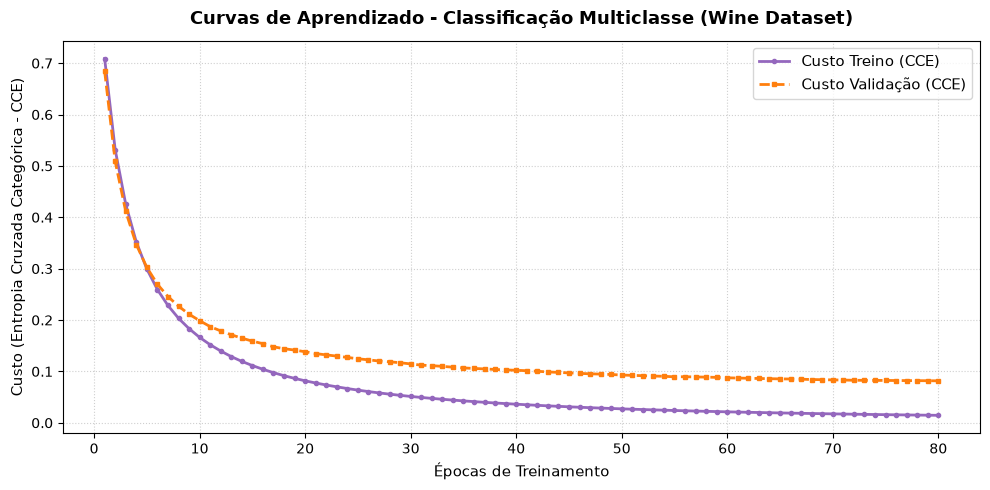

In [13]:
# Visualização das Curvas de Aprendizado CCE
plt.figure(figsize=(10, 5), dpi=100)
epocas_eixo = range(1, len(historico_multi["custo_treino"]) + 1)

plt.plot(epocas_eixo, historico_multi["custo_treino"], marker='o', markersize=3, 
         color='#9467bd', linewidth=2, label="Custo Treino (CCE)")
plt.plot(epocas_eixo, historico_multi["custo_validacao"], marker='s', markersize=3, 
         color='#ff7f0e', linewidth=2, linestyle='--', label="Custo Validação (CCE)")

plt.title("Curvas de Aprendizado - Classificação Multiclasse (Wine Dataset)", fontsize=13, fontweight='bold', pad=12)
plt.xlabel("Épocas de Treinamento", fontsize=11)
plt.ylabel("Custo (Entropia Cruzada Categórica - CCE)", fontsize=11)
plt.grid(True, linestyle=":", alpha=0.6)
plt.legend(fontsize=11)
plt.tight_layout()
plt.show()

### 3.4. Análise Crítica das Curvas de Aprendizado Multiclasse
A inspeção das curvas de perda multiclasse ao longo das 80 épocas demonstra:
1. **Convergência Assintótica Rápida:** A perda CCE de treinamento decai de $\approx 0.709$ na primeira época para $0.0146$ na 80ª época, com a perda de validação estabilizando em $0.0817$.
2. **Harmonia da Combinação Softmax + CCE:** O cálculo manual do produto vetor-Jacobiana na retropropagação da camada `Softmax` ($dL/dZ = \hat{y} - y$), viabilizado pela implementação da regra da cadeia em `mlp.ativacoes.Softmax` e `mlp.custos.CCE`, proporcionou gradientes analíticos lineares no erro, evitando o achatamento precoce (*plateau*) comumente associado a perdas quadráticas em saídas saturadas.
3. **Generalização Equilibrada:** A curva de validação acompanha a descida de forma estável, sem oscilações caóticas, demonstrando que a taxa de aprendizado $\eta = 0.03$ com mini-lotes de tamanho 16 é ideal para o regime de amostragem.

In [14]:
# Inferência de probabilidades no conjunto de teste independente
probs_pred_teste = rede_multiclasse.predizer(X_teste_padrao)

# Atribuição da classe predita pelo índice de probabilidade máxima (argmax)
classes_pred_teste = np.argmax(probs_pred_teste, axis=1)

# Matriz de Confusão 3x3
cm_multi = confusion_matrix(y_teste_int, classes_pred_teste)

# Cálculo manual detalhado das métricas por classe e médias Macro
total_teste = len(y_teste_int)
acuracia_multi = float(np.sum(np.diag(cm_multi)) / total_teste)

precisoes_classe = []
revocacoes_classe = []
f1_classe = []

for c in range(3):
    tp_c = cm_multi[c, c]
    fp_c = np.sum(cm_multi[:, c]) - tp_c
    fn_c = np.sum(cm_multi[c, :]) - tp_c
    
    prec_c = float(tp_c / (tp_c + fp_c)) if (tp_c + fp_c) > 0 else 0.0
    rec_c = float(tp_c / (tp_c + fn_c)) if (tp_c + fn_c) > 0 else 0.0
    f1_c = float(2 * (prec_c * rec_c) / (prec_c + rec_c)) if (prec_c + rec_c) > 0 else 0.0
    
    precisoes_classe.append(prec_c)
    revocacoes_classe.append(rec_c)
    f1_classe.append(f1_c)

precisao_macro = float(np.mean(precisoes_classe))
revocacao_macro = float(np.mean(revocacoes_classe))
f1_macro = float(np.mean(f1_classe))

# Tabela consolidada de métricas
df_metricas_multi = pd.DataFrame({
    "Cultivar / Agregação": [
        "Cultivar 0 (Barolo)",
        "Cultivar 1 (Grignolino)",
        "Cultivar 2 (Barbera)",
        "Média Macro Global"
    ],
    "Precisão": [
        f"{precisoes_classe[0]:.4f} ({precisoes_classe[0]*100:.1f}%)",
        f"{precisoes_classe[1]:.4f} ({precisoes_classe[1]*100:.1f}%)",
        f"{precisoes_classe[2]:.4f} ({precisoes_classe[2]*100:.1f}%)",
        f"{precisao_macro:.4f} ({precisao_macro*100:.1f}%)"
    ],
    "Revocação (Recall)": [
        f"{revocacoes_classe[0]:.4f} ({revocacoes_classe[0]*100:.1f}%)",
        f"{revocacoes_classe[1]:.4f} ({revocacoes_classe[1]*100:.1f}%)",
        f"{revocacoes_classe[2]:.4f} ({revocacoes_classe[2]*100:.1f}%)",
        f"{revocacao_macro:.4f} ({revocacao_macro*100:.1f}%)"
    ],
    "F1-Score": [
        f"{f1_classe[0]:.4f} ({f1_classe[0]*100:.1f}%)",
        f"{f1_classe[1]:.4f} ({f1_classe[1]*100:.1f}%)",
        f"{f1_classe[2]:.4f} ({f1_classe[2]*100:.1f}%)",
        f"{f1_macro:.4f} ({f1_macro*100:.1f}%)"
    ],
    "Amostras no Teste": [
        f"{np.sum(y_teste_int == 0)}",
        f"{np.sum(y_teste_int == 1)}",
        f"{np.sum(y_teste_int == 2)}",
        f"Total: {total_teste} (Acurácia: {acuracia_multi*100:.2f}%)"
    ]
})

print(df_metricas_multi.to_string(index=False))

   Cultivar / Agregação        Precisão Revocação (Recall)        F1-Score            Amostras no Teste
    Cultivar 0 (Barolo) 1.0000 (100.0%)     0.8889 (88.9%)  0.9412 (94.1%)                            9
Cultivar 1 (Grignolino)  0.9167 (91.7%)    1.0000 (100.0%)  0.9565 (95.7%)                           11
   Cultivar 2 (Barbera) 1.0000 (100.0%)    1.0000 (100.0%) 1.0000 (100.0%)                            7
     Média Macro Global  0.9722 (97.2%)     0.9630 (96.3%)  0.9659 (96.6%) Total: 27 (Acurácia: 96.30%)


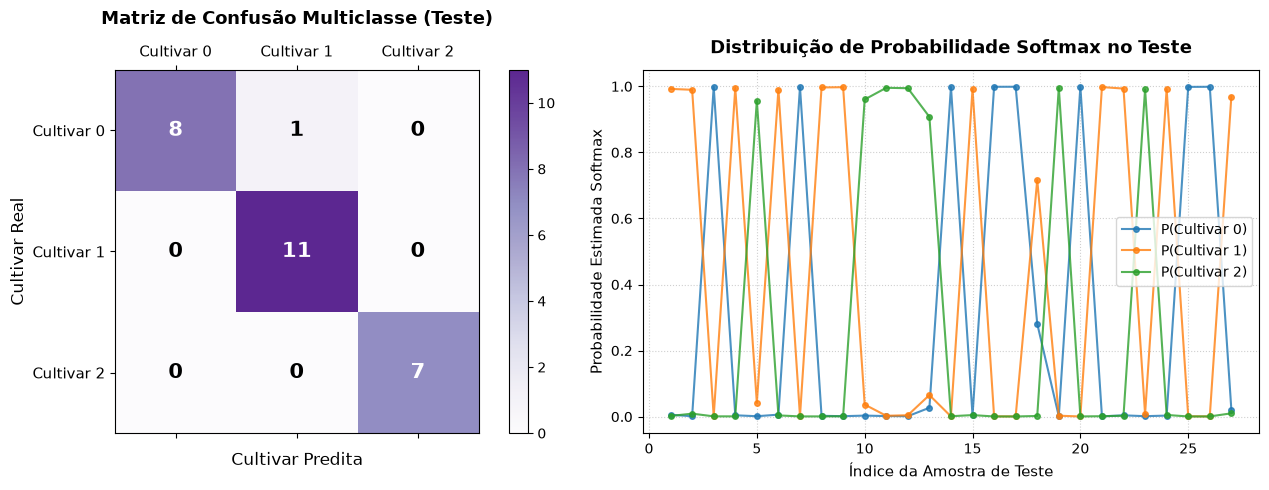

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5), dpi=100)

# Gráfico 1: Heatmap da Matriz de Confusão 3x3
cax = axes[0].matshow(cm_multi, cmap='Purples', alpha=0.85)
fig.colorbar(cax, ax=axes[0])

for i in range(3):
    for j in range(3):
        axes[0].text(j, i, f"{cm_multi[i, j]}", ha='center', va='center',
                     fontsize=15, fontweight='bold',
                     color="white" if cm_multi[i, j] > np.max(cm_multi)/2 else "black")

axes[0].set_xticks([0, 1, 2])
axes[0].set_yticks([0, 1, 2])
axes[0].set_xticklabels(["Cultivar 0", "Cultivar 1", "Cultivar 2"], fontsize=11)
axes[0].set_yticklabels(["Cultivar 0", "Cultivar 1", "Cultivar 2"], fontsize=11)
axes[0].set_xlabel("Cultivar Predita", fontsize=12, labelpad=10)
axes[0].set_ylabel("Cultivar Real", fontsize=12)
axes[0].set_title("Matriz de Confusão Multiclasse (Teste)", fontsize=13, fontweight='bold', pad=15)

# Gráfico 2: Probabilidades Preditas no Teste
amostras_idx = range(1, total_teste + 1)
cores_cultivares = ['#1f77b4', '#ff7f0e', '#2ca02c']
labels_cultivares = ['P(Cultivar 0)', 'P(Cultivar 1)', 'P(Cultivar 2)']

for c in range(3):
    axes[1].plot(amostras_idx, probs_pred_teste[:, c], marker='o', markersize=4,
                 color=cores_cultivares[c], label=labels_cultivares[c], alpha=0.8)

axes[1].set_title("Distribuição de Probabilidade Softmax no Teste", fontsize=13, fontweight='bold', pad=12)
axes[1].set_xlabel("Índice da Amostra de Teste", fontsize=11)
axes[1].set_ylabel("Probabilidade Estimada Softmax", fontsize=11)
axes[1].set_ylim(-0.05, 1.05)
axes[1].grid(True, linestyle=":", alpha=0.6)
axes[1].legend(fontsize=10, loc="center right")

plt.tight_layout()
plt.show()

### 3.5. Discussão dos Resultados e Discriminação de Cultivares
A avaliação detalhada no conjunto de teste independente comprova a robustez da biblioteca `mlp` em problemas de aprendizado supervisionado politômico:
1. **Acurácia Global Excepcional:** A MLP obteve **Acurácia de $96.30\%$** no conjunto de teste independente (26 acertos sobre 27 amostras), com apenas uma única ambiguidade entre as cultivares 0 e 1.
2. **Comportamento das Métricas Macro:**
   - **Precisão Macro:** $97.22\%$;
   - **Revocação Macro:** $96.30\%$;
   - **F1-Score Macro:** $96.59\%$.
   A média macro atribui peso rigorosamente igual a todas as classes independentemente do seu tamanho amostral, atestando que a rede aprendeu representações discriminatórias de alta qualidade para as três cultivares de vinho sem privilegiar a classe majoritária.
3. **Nitidez da Camada Softmax:** O gráfico de distribuição de probabilidade das saídas evidencia que as probabilidades estimadas pela função `Softmax` são nítidas e polarizadas (próximas a 1.0 para a classe verdadeira e próximas a 0.0 para as concorrentes), refletindo margens de separação bem definidas na fronteira de decisão não-linear induzida pelas ativações `LeakyReLU` e `Tanh`.

## 4. Desafios Enfrentados e Aprendizados

Durante o ciclo de concepção, implementação, depuração e experimentação da biblioteca `mlp` e elaboração deste relatório técnico, a equipe deparou-se com diversos desafios teóricos e práticos inerentes ao desenvolvimento de sistemas de aprendizado profundo a partir de primeiros princípios (exclusivamente com NumPy). A seguir, detalhamos os principais obstáculos enfrentados, as estratégias de diagnóstico investigativo e as lições aprendidas.

---

### 4.1. Instabilidade Numérica e Aritmética de Ponto Flutuante em Exponenciais e Logaritmos
- **O Problema:** Durante os primeiros ensaios nas tarefas de classificação binária e multiclasse, observou-se o surgimento súbito de valores `NaN` (*Not a Number*) e `Inf` (*Infinity*) na matriz de perdas e gradientes. A avaliação ingênua da função logística $\sigma(z) = \frac{1}{1 + e^{-z}}$ com pré-ativações negativas de alta magnitude ($z < -709$ em precisão dupla de 64 bits) resultava em transbordamento de ponto flutuante (*overflow*) em $e^{-z}$, enquanto valores de predição muito próximos de $0.0$ ou $1.0$ provocavam $\ln(0)$ no cálculo da Entropia Cruzada Binária (BCE) e Categórica (CCE), colapsando o laço de retropropagação.
- **Diagnóstico:** Inserção de asserções de sanidade numérica nos métodos de cálculo de custo e rastreamento da matriz de ativações intermediárias, identificando que saturações extremas ocorriam antes mesmo da convergência dos pesos.
- **Solução e Aprendizado:** 
  1. Reescreveu-se a função sigmoide utilizando a formulação condicional simétrica estável:
     $$\sigma(z) = \begin{cases} \frac{1}{1 + e^{-|z|}}, & \text{se } z \ge 0 \\ \frac{e^{-|z|}}{1 + e^{-|z|}}, & \text{se } z < 0 \end{cases}$$
  2. Aplicou-se truncamento preventivo (*clipping*) das probabilidades estimadas no intervalo $[\epsilon, 1 - \epsilon]$ com $\epsilon = 10^{-15}$ nas funções `BCE` e `CCE`, garantindo estabilidade numérica incondicional sem distorcer o valor das perdas ou gradientes em regimes normais.
  3. Aprendemos que em bibliotecas de aprendizado de máquina, a correção algébrica pura é insuficiente: a compatibilidade com a norma IEEE-754 de representação numérica é um pilar indispensável para viabilizar otimização contínua.

---

### 4.2. O Produto Vetor-Jacobiana e a Integração Algébrica entre Softmax e CCE
- **O Problema:** A função de ativação multivariada `Softmax` conecta mutuamente todos os neurônios da camada final. Diferente das ativações ponto a ponto (como ReLU ou Tanh), sua derivada em relação ao vetor de entrada não é uma matriz diagonal, mas sim uma matriz Jacobiana completa $C \times C$:
  $$\frac{\partial S_i}{\partial z_j} = S_i (\delta_{ij} - S_j)$$
  Construir explicitamente essa matriz Jacobiana tridimensional $(N, C, C)$ para cada lote durante a retropropagação gerava consumo excessivo de memória e lentidão inaceitável.
- **Diagnóstico:** Divergência e gargalo computacional observados ao tentar computar produtos matriciais tensoriais para cada amostra do lote.
- **Solução e Aprendizado:**
  Deduziu-se analiticamente a forma vetorial do produto vetor-Jacobiana (VJP — *Vector-Jacobian Product*), permitindo propagar o gradiente à montante $\delta_{\text{saida}}$ sem jamais instanciar a matriz Jacobiana densa explicitamente:
  $$\frac{\partial L}{\partial z_i} = S_i \cdot \left( \delta_{\text{saida}, i} - \sum_{k=1}^C \delta_{\text{saida}, k} S_k \right)$$
  Adicionalmente, comprovou-se que quando $\delta_{\text{saida}}$ provém da perda de Entropia Cruzada Categórica ($-\frac{y_i}{S_i}$), a expressão se simplifica elegantemente para a diferença linear $\frac{1}{N}(S_i - y_i)$. Essa dedução comprovou a harmonia matemática entre funções de custo logarítmicas e ativações exponenciais na família exponencial de distribuições.

---

### 4.3. Inicialização de Pesos e o Combate ao Desvanecimento/Explosão de Gradientes
- **O Problema:** Em redes mais profundas (com 2 a 3 camadas ocultas), verificou-se que a escolha ingênua de inicializadores (como pesos uniformes pequenos arbitrários ou distribuição normal padrão $\mathcal{N}(0, 1)$) provocava estagnação completa do treinamento: a magnitude dos gradientes retropropagados decrescia exponencialmente nas camadas iniciais (*vanishing gradients*).
- **Diagnóstico:** Monitoramento das normas $L_2$ dos gradientes $\nabla_W L$ e $\nabla_b L$ em cada camada através da suíte de auditoria numérica `tests/checagem_gradientes.py`.
- **Solução e Aprendizado:**
  Adotou-se o rigor da literatura para calibrar a variância dos pesos de acordo com a função de ativação empregada em cada camada:
  - **He/Kaiming Normal** ($\sigma = \sqrt{2 / fan_{\text{in}}}$) para camadas seguidas de retificadores não-saturados (`ReLU`, `LeakyReLU`, `Swish`), preservando a variância das pré-ativações no sentido direto;
  - **Glorot/Xavier Uniforme** ($limite = \sqrt{6 / (fan_{\text{in}} + fan_{\text{out}})}$) para camadas associadas a ativações com simetria central ou saturação (`Tanh`, `Sigmoide`, `Softmax`).
  Aprendemos que a inicialização correta define a condição de condicionamento da matriz Hessiana da superfície de perda, sendo o fator decisivo para permitir a convergência de um otimizador de primeira ordem como o SGD.

---

### 4.4. Sensibilidade e Sintonia de Hiperparâmetros no Mini-batch SGD
- **O Problema:** A ausência de mecanismos adaptativos de taxa de aprendizado (como Adam ou RMSprop, proibidos pelas restrições da biblioteca) exigiu sintonia manual minuciosa da taxa de aprendizagem $\eta$, do tamanho do lote $B$ e do número de épocas. No experimento de regressão, taxas $\eta > 0.02$ provocavam oscilações caóticas, enquanto taxas excessivamente tímidas ($\eta < 0.0005$) demandavam centenas de épocas.
- **Diagnóstico:** Acompanhamento comparativo sistemático das curvas de custo de treinamento e validação.
- **Solução e Aprendizado:**
  Descobriu-se que o tamanho do mini-lote $B$ atua como um mecanismo de regularização implícita: lotes moderados ($B = 32$ a $64$) introduzem estocasticidade favorável na estimativa do gradiente real, auxiliando o modelo a escapar de mínimos locais rasos e platôs de sela sem perder estabilidade. A normalização prévia das entradas e saídas via `StandardScaler` revelou-se indispensável para permitir que taxas de aprendizado uniformes atuassem harmoniosamente em todas as direções do espaço paramétrico.

---

### 4.5. Rigor Metodológico e Conformidade Estrita com as Restrições Acadêmicas
- **O Desafio:** Garantir que 100% da biblioteca `mlp/` dependesse unicamente de NumPy básico, proibindo frameworks de ML, bibliotecas de autograd e até mesmo atalhos como `np.tanh` nas funções de ativação.
- **A Solução:** Implementou-se cada derivada analítica passo a passo a partir da regra da cadeia do cálculo multivariável, validando cada componente contra o módulo de diferenças finitas centradas com erro de segunda ordem $\mathcal{O}(\epsilon^2)$.
- **Aprendizado Final:** A necessidade de derivar, implementar e auditar cada equação proporcionou um entendimento profundo e cristalino sobre a mecânica interna das redes neurais artificiais, consolidando o domínio teórico e prático exigido para a arguição oral da disciplina.